In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Default Dataset.csv to Default Dataset.csv


In [ ]:
import pandas as pd

df = pd.read_csv('Default Dataset.csv')

print(df.head())
print(df.columns)

   2.000000000000001   -0.16626153678084954
0                2.5              -0.168051
1                3.0              -0.176037
2                3.5               0.139800
3                4.0               0.102884
4                4.5               0.266260
Index(['2.000000000000001', ' -0.16626153678084954'], dtype='object')


In [ ]:
time = df.iloc[:, 0].values
ecg  = df.iloc[:, 1].values

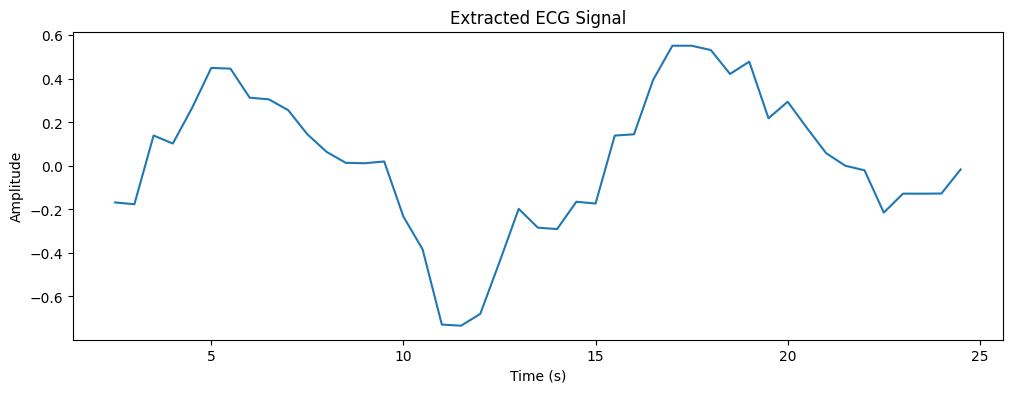

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))
plt.plot(time, ecg)
plt.title("Extracted ECG Signal")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.show()

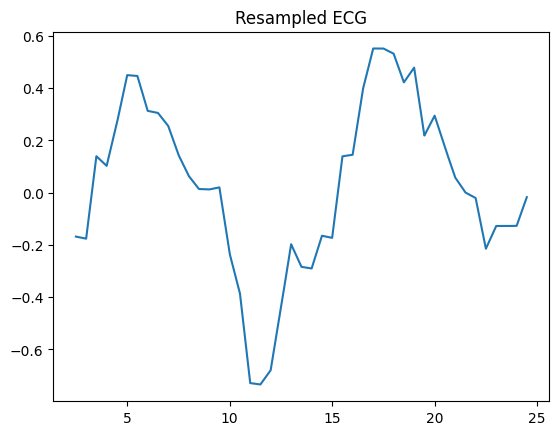

In [ ]:
import numpy as np
from scipy.interpolate import interp1d

# Create uniform time axis
fs = 250  # assume 250 Hz (good default)
t_uniform = np.arange(time.min(), time.max(), 1/fs)

interp_func = interp1d(time, ecg, kind='linear')
ecg_uniform = interp_func(t_uniform)

plt.plot(t_uniform, ecg_uniform)
plt.title("Resampled ECG")
plt.show()

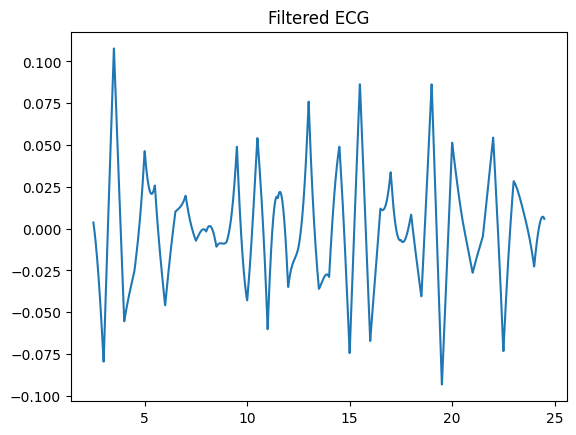

In [ ]:
from scipy.signal import butter, filtfilt

def bandpass(signal, low, high, fs):
    nyq = 0.5 * fs
    b, a = butter(4, [low/nyq, high/nyq], btype='band')
    return filtfilt(b, a, signal)

ecg_filtered = bandpass(ecg_uniform, 0.5, 40, fs)

plt.plot(t_uniform, ecg_filtered)
plt.title("Filtered ECG")
plt.show()

In [1]:
from scipy.signal import find_peaks

peaks, _ = find_peaks(ecg_filtered, distance=fs*0.6)

plt.figure(figsize=(12,4))
plt.plot(t_uniform, ecg_filtered)
plt.plot(t_uniform[peaks], ecg_filtered[peaks], 'ro')
plt.title("R Peak Detection")
plt.show()

NameError: name 'ecg_filtered' is not defined

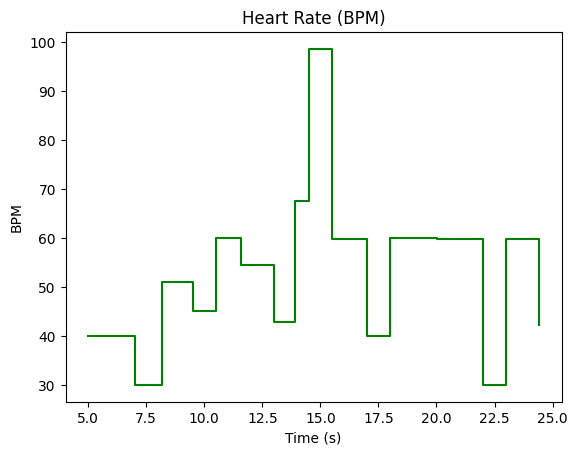

In [ ]:
rr = np.diff(t_uniform[peaks])
hr = 60 / rr

t_hr = t_uniform[peaks][1:]

plt.step(t_hr, hr, where='post', color='green')
plt.title("Heart Rate (BPM)")
plt.xlabel("Time (s)")
plt.ylabel("BPM")
plt.show()

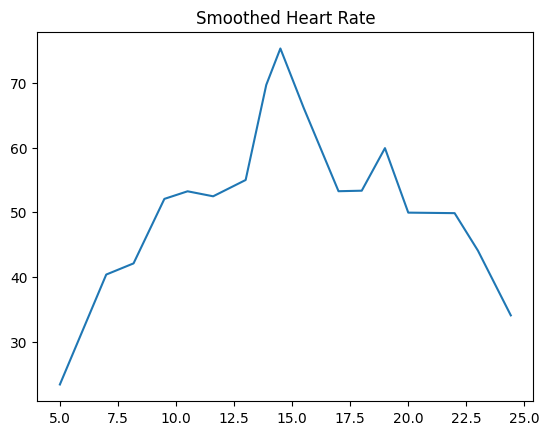

In [ ]:
hr_smooth = np.convolve(hr, np.ones(3)/3, mode='same')

plt.plot(t_hr, hr_smooth)
plt.title("Smoothed Heart Rate")
plt.show()

In [ ]:
from scipy.signal import welch
import numpy as np
def compute_snr(signal, fs, band_low, band_high):
    f, Pxx = welch(signal, fs, nperseg=256)

    # Signal power in desired band
    signal_power = np.sum(Pxx[(f >= band_low) & (f <= band_high)])

    # Noise = rest of spectrum
    noise_power = np.sum(Pxx) - signal_power

    # Avoid divide-by-zero
    if noise_power == 0:
        return np.inf

    return 10 * np.log10(signal_power / noise_power)
fs = len(time_common) / 60   # if your total duration is 60 sec
print("Sampling Frequency:", fs)
snr_ecg = compute_snr(ecg_r, fs, 0.5, 40)

print("ECG SNR (dB):", snr_ecg)

NameError: name 'time_common' is not defined